Loading model from ./training_results_rad/best_model.pth ...
Model weights loaded successfully.
Scanning images in ./dataset_real_white_theme ...
Found 180 images. Starting inference...


100%|██████████| 180/180 [00:00<00:00, 450.62it/s]
d:\anaconda3\envs\pytorch1_12_1\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
d:\anaconda3\envs\pytorch1_12_1\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
d:\anaconda3\envs\pytorch1_12_1\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_sta


PREDICTION SUMMARY
Total Images: 140
Accuracy:     14.29%
----------------------------------------

Detailed Report:
              precision    recall  f1-score   support

        2ASK     0.1429    1.0000    0.2500        20
        8PSK     0.0000    0.0000    0.0000        20
        BPSK     0.0000    0.0000    0.0000        20
        FSK2     0.0000    0.0000    0.0000        20
       OQPSK     0.0000    0.0000    0.0000        20
    PI4DQPSK     0.0000    0.0000    0.0000        20
        QPSK     0.0000    0.0000    0.0000        20

    accuracy                         0.1429       140
   macro avg     0.0204    0.1429    0.0357       140
weighted avg     0.0204    0.1429    0.0357       140


[Saved] Detailed results saved to: ./Up_result/D/prediction_results.csv
[Saved] Confusion matrix saved to: ./Up_result/D/prediction_confusion_matrix.png


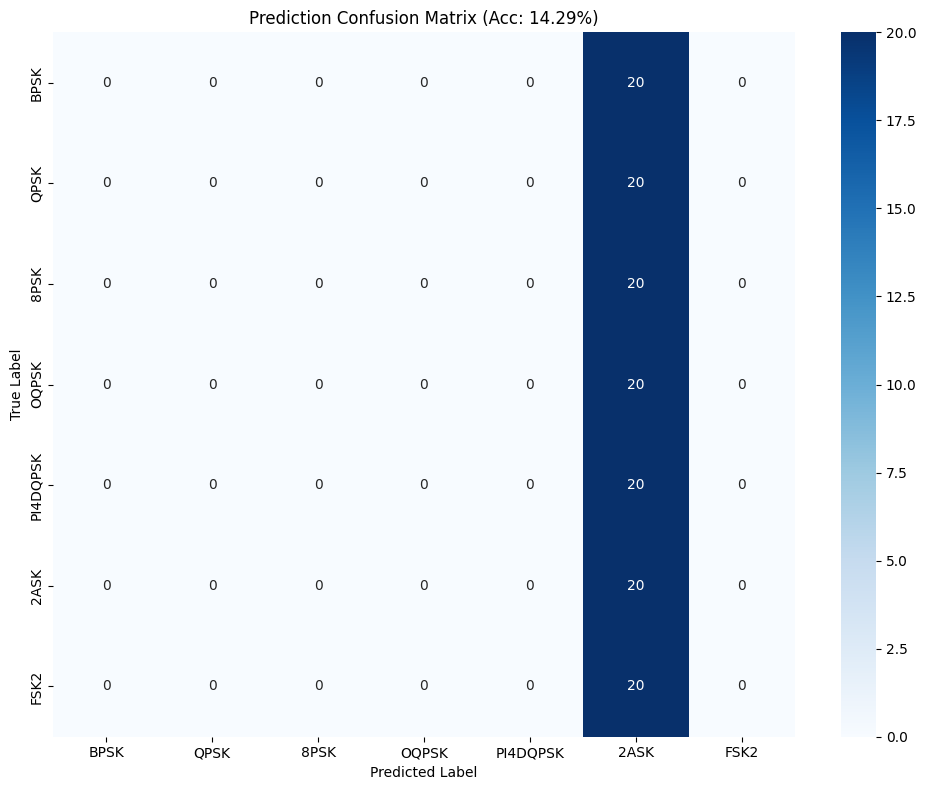

In [2]:
# predict_rad.py
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from tqdm import tqdm
import numpy as np

# ================= 配置区域 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 1. 模型路径 (训练好的最佳权重)
MODEL_PATH = "./training_results_rad/best_model.pth"

# 2. 待预测的数据文件夹 (这里指向真实数据文件夹)
# 注意：该文件夹下应该有以类别命名的子文件夹 (如 BPSK, QAM16...)
# 如果是扁平目录(无子文件夹)，代码逻辑需要微调
TARGET_DIR = "./dataset_real_white_theme"

# 3. 结果保存路径
OUTPUT_CSV = "./Up_result/D/prediction_results.csv"
OUTPUT_CM = "./Up_result/D/prediction_confusion_matrix.png"

# 4. 类别定义 (必须与训练时完全一致，顺序不能乱)
CLASS_NAMES = [
    "BPSK", "QPSK", "8PSK", "OQPSK", "PI4DQPSK", 
    "16QAM", "32QAM", "64QAM", 
    "2ASK", "16APSK", "32APSK", "FSK2"
]
IMAGE_SIZE = 64

# ================= 模型定义 (必须与训练代码一致) =================
class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            # 输入通道 3 (R, A, D)
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128), 
            nn.ReLU(), 
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

# ================= 预测逻辑 =================
def main():
    # 1. 初始化模型
    print(f"Loading model from {MODEL_PATH} ...")
    model = TinyCNN(len(CLASS_NAMES)).to(DEVICE)
    
    if os.path.exists(MODEL_PATH):
        model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
        print("Model weights loaded successfully.")
    else:
        print("Error: Model file not found! Please train the model first.")
        return

    model.eval()

    # 2. 准备数据预处理
    transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor()
    ])

    # 3. 扫描文件
    print(f"Scanning images in {TARGET_DIR} ...")
    image_paths = list(Path(TARGET_DIR).rglob("*.png"))
    
    if len(image_paths) == 0:
        print("No images found.")
        return

    print(f"Found {len(image_paths)} images. Starting inference...")

    results = []
    y_true = []
    y_pred = []

    # 4. 批量推理
    with torch.no_grad():
        for img_path in tqdm(image_paths):
            try:
                # 获取真实标签 (根据父文件夹名)
                # 例如 .../real_test/BPSK/img.png -> true_label = "BPSK"
                true_label_str = img_path.parent.name
                
                # 如果文件夹名不在我们的类别列表里，跳过或标记未知
                if true_label_str not in CLASS_NAMES:
                    # 也可以选择跳过 continue
                    # 这里为了演示，我们假设只预测已知类别
                    continue

                # 读取并处理图片
                img = Image.open(img_path).convert("RGB")
                tensor = transform(img).unsqueeze(0).to(DEVICE) # (1, 3, 64, 64)

                # 推理
                outputs = model(tensor)
                
                # 计算概率 (Softmax)
                probs = F.softmax(outputs, dim=1)
                
                # 获取最大概率和对应索引
                confidence, pred_idx = torch.max(probs, 1)
                
                pred_idx = pred_idx.item()
                confidence = confidence.item()
                pred_label_str = CLASS_NAMES[pred_idx]

                # 记录结果
                is_correct = (true_label_str == pred_label_str)
                
                results.append({
                    "Filename": img_path.name,
                    "True_Label": true_label_str,
                    "Pred_Label": pred_label_str,
                    "Confidence": round(confidence, 4),
                    "Correct": is_correct
                })
                
                y_true.append(true_label_str)
                y_pred.append(pred_label_str)

            except Exception as e:
                print(f"Error processing {img_path}: {e}")

    # 5. 统计与输出
    if not results:
        print("No valid predictions made.")
        return

    df = pd.DataFrame(results)
    accuracy = accuracy_score(y_true, y_pred)
    
    print("\n" + "="*40)
    print(f"PREDICTION SUMMARY")
    print("="*40)
    print(f"Total Images: {len(df)}")
    print(f"Accuracy:     {accuracy:.2%}")
    print("-" * 40)
    
    # 打印每个类别的详细报告
    print("\nDetailed Report:")
    print(classification_report(y_true, y_pred, digits=4))

    # 保存 CSV
    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\n[Saved] Detailed results saved to: {OUTPUT_CSV}")

    # 6. 绘制混淆矩阵 (只显示出现的类别)
    present_labels = sorted(list(set(y_true + y_pred)), key=lambda x: CLASS_NAMES.index(x) if x in CLASS_NAMES else 999)
    
    cm = confusion_matrix(y_true, y_pred, labels=present_labels)
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=present_labels, yticklabels=present_labels)
    plt.title(f"Prediction Confusion Matrix (Acc: {accuracy:.2%})")
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(OUTPUT_CM)
    print(f"[Saved] Confusion matrix saved to: {OUTPUT_CM}")

if __name__ == "__main__":
    main()